# 07 · World-action models: from video to control
**Student edition.**

**Cosmos Policy 2B + UVA (Unified Video Action) · 5 questions · 3 short coding TODOs.**

**From video prediction to robot commands — and deciding when video is useful.**

- **Colab:** select a T4 GPU and run the four collapsed setup cells.
- First run downloads **5.73 GB** of weights + a small code/data archive; figures are embedded.
- Full pretrained weights, FP32, no training. Models load sequentially.
- Predict → run → explain. Fill in the short answer cells below the experiments.

Cosmos Policy: [ICLR 2026](https://proceedings.iclr.cc/paper_files/paper/2026/hash/748becc400a57c0e31cfe6a2e7951467-Abstract-Conference.html) · UVA: [RSS 2025](https://www.roboticsproceedings.org/rss21/p074.html).

**Route:** read actions → fix known slots → change actions → rank imagined futures → skip video with UVA.

In [1]:
#@title 1 · Dependencies and GPU (preserves Colab's torch/torchvision)
import importlib.metadata as metadata
import os, subprocess, sys
from pathlib import Path
from packaging.requirements import Requirement
ROOT=Path(os.environ.get('SEMINAR07_ROOT','/content/seminar07_runtime' if Path('/content').exists() else './seminar07_runtime')).resolve()
ROOT.mkdir(parents=True,exist_ok=True)
os.environ['SDL_VIDEODRIVER']='dummy'
os.environ['TOKENIZERS_PARALLELISM']='false'
os.environ['HF_HUB_DISABLE_XET']='1'
requirements=['einops==0.8.1','safetensors==0.6.2','huggingface-hub==0.35.3',
    'transformers==4.57.1','gdown==6.4.2','hydra-core==1.3.7','dill==0.4.1',
    'timm==1.0.30','kornia==0.8.3','gym==0.26.2','pymunk==6.11.1','pygame==2.6.1',
    'shapely>=2,<3','scikit-image>=0.22,<1','opencv-python-headless>=4.8,<4.12',
    'zarr==2.18.7','numcodecs==0.15.1','numpy>=1.26,<3','scipy>=1.11,<2',
    'pillow>=10,<13','matplotlib>=3.8,<4','pandas>=2.2,<3']
pending=[]
for spec in requirements:
    req=Requirement(spec)
    try:version=metadata.version(req.name)
    except metadata.PackageNotFoundError:version=None
    if version is None or not req.specifier.contains(version):pending.append(spec)
if pending:
    pins=[]
    for name in ['torch','torchvision','numpy','pillow','matplotlib','pandas']:
        try:pins.append(f'{name}=={metadata.version(name)}')
        except metadata.PackageNotFoundError:pass
    constraints=ROOT/'runtime_constraints.txt';constraints.write_text('\n'.join(pins))
    subprocess.run([sys.executable,'-m','pip','install','--quiet','-c',str(constraints),*pending],check=True)
import torch
assert tuple(map(int,torch.__version__.split('+')[0].split('.')[:2]))>=(2,5),'PyTorch >=2.5 required'
assert torch.cuda.is_available(),'Select a GPU runtime in Colab'
print(torch.__version__,torch.cuda.get_device_name(0))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 485.8/485.8 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 564.3/564.3 kB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 109.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 77.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.3/211.3 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 110.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 MB 43.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.35.3 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.35.3 which is incompatible.
diffusers 0.40.0 requires safetensors>=0.8.0, but you have safetensors 0.6.2 which is incompatible.


2.11.0+cu128 Tesla T4


In [2]:
#@title 2 · Download pinned source code, sample, and licenses
import hashlib, os, sys, urllib.request, zipfile
from pathlib import Path

ASSET_BASE_URL = os.environ.get('SEMINAR07_ASSET_BASE_URL',
    'https://raw.githubusercontent.com/wingrune/multimodal-vla-course/main/07-world-action-models/assets').rstrip('/')
ARCHIVE_NAME = 'seminar07_bundle.zip'
ARCHIVE_SHA256 = '977818a7bc22a498b0a1ad933059657838d90eed348a2f6639c46424254cdd69'
candidates = [Path('assets') / ARCHIVE_NAME, Path('07-world-action-models/assets') / ARCHIVE_NAME,
              Path('multimodal-vla-course/07-world-action-models/assets') / ARCHIVE_NAME, ROOT / ARCHIVE_NAME]
archive_path = next((p for p in candidates if p.is_file()
    and hashlib.sha256(p.read_bytes()).hexdigest() == ARCHIVE_SHA256), None)
if archive_path is None:
    url = f'{ASSET_BASE_URL}/{ARCHIVE_NAME}'
    print(f'Downloading seminar data and source excerpts: {url}', flush=True)
    archive_path = ROOT / ARCHIVE_NAME
    temporary = archive_path.with_suffix('.zip.part')
    try:
        with urllib.request.urlopen(url, timeout=30) as response, temporary.open('wb') as output:
            while chunk := response.read(128 * 1024):
                output.write(chunk)
        if hashlib.sha256(temporary.read_bytes()).hexdigest() != ARCHIVE_SHA256:
            raise RuntimeError('Archive checksum mismatch')
        temporary.replace(archive_path)
    except Exception as exc:
        temporary.unlink(missing_ok=True)
        raise RuntimeError(f'Could not download {url}. Check the internet connection or put '
                           f'{ARCHIVE_NAME} in assets/ beside the notebook. Details: {exc}') from exc
with zipfile.ZipFile(archive_path) as archive:
    if any(Path(p).is_absolute() or '..' in Path(p).parts for p in archive.namelist()):
        raise RuntimeError('Unexpected archive member path')
    archive.extractall(ROOT)
sys.path.insert(0, str(ROOT / 'sources'))
print('Pinned code and sample data ready:', ROOT)

Pinned code and sample data ready: /content/seminar07_runtime


In [3]:
#@title 3 · Download and verify the three weight files
from weights import get_weights
WEIGHTS=get_weights(ROOT)

Cosmos-Policy-LIBERO-Predict2-2B.pt:   0%|          | 0.00/3.91G [00:00<?, ?B/s]

SHA-256 OK: Cosmos-Policy-LIBERO-Predict2-2B.pt


Wan2.1_VAE.pth:   0%|          | 0.00/508M [00:00<?, ?B/s]

SHA-256 OK: Wan2.1_VAE.pth


Downloading...
From (original): https://drive.google.com/uc?id=1OduHcxfc2hqUYSccMQNf9g-vAt-q2UhF
From (redirected): https://drive.google.com/uc?id=1OduHcxfc2hqUYSccMQNf9g-vAt-q2UhF&confirm=t&uuid=94275555-5656-4e87-970f-32fd5680123c
To: /content/seminar07_runtime/weights/uva_pusht.ckpt.part
100%|██████████| 1.31G/1.31G [00:26<00:00, 49.4MB/s]


SHA-256 OK: uva_pusht.ckpt


In [4]:
#@title 4 · Supplied experiment and plotting helpers
"""Supplied experiments for Seminar 07. All model calls use full pretrained weights."""
import gc, hashlib, inspect, json, os, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from cosmos_turing import CosmosPolicyTuring, SLOTS
from uva_adapter import UVALab, seed_all
from wam_cosmos import reference as cosmos_ref

METRICS={'measurements':[], 'checks':{}, 'hosted_colab_t4_tested':False}
torch.set_num_threads(4)
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False

def measure(name,fn,repeats=1):
    torch.cuda.synchronize();torch.cuda.reset_peak_memory_stats()
    times=[]
    for _ in range(repeats):
        start=time.perf_counter();result=fn();torch.cuda.synchronize();times.append(time.perf_counter()-start)
    row={'operation':name,'seconds':float(np.median(times)),
         'allocated_GiB':torch.cuda.max_memory_allocated()/2**30,
         'reserved_GiB':torch.cuda.max_memory_reserved()/2**30,'repeats':repeats}
    METRICS['measurements'].append(row)
    display(pd.DataFrame([row]).round(3))
    return result

def check(name,actual,expected,atol=1e-5,rtol=1e-5):
    torch.testing.assert_close(torch.as_tensor(actual),torch.as_tensor(expected),atol=atol,rtol=rtol,check_dtype=False)
    METRICS['checks'][name]=True
    print('PASS:',name)

def source_excerpt(obj,start=None,lines=22):
    text=inspect.getsource(obj).splitlines()
    if start:
        pos=next(i for i,s in enumerate(text) if start in s);text=text[pos:]
    print('\n'.join(text[:lines]))

def gallery(images,titles,figsize=None):
    fig,axes=plt.subplots(1,len(images),figsize=figsize or (3*len(images),3),squeeze=False)
    for ax,img,title in zip(axes[0],images,titles):ax.imshow(img);ax.set_title(title);ax.axis('off')
    fig.tight_layout();plt.show()

def cosmos_gallery(lab,sample):
    future=measure('Cosmos: decode causal prefix',lambda:lab.decode(sample))
    gallery([lab.images[1],future[1],lab.images[0],future[0]],
            ['Current primary','Predicted primary at t+16','Current wrist','Predicted wrist at t+16'])
    return future

def readout_experiment(lab,sample,readout):
    frame=sample[:,:,4]
    got=readout(frame,16,7)
    check('Action readout matches upstream',got,lab.actions(sample))
    # A non-divisible length checks that a partial last repetition is ignored.
    x=torch.arange(3*5*5,dtype=torch.float32).reshape(1,3,5,5)
    check('Partial repeat is excluded',readout(x,2,3),x.flatten(1)[:,:72].reshape(1,12,2,3).mean(1))
    tiled=cosmos_ref.replace_latent_with_action_chunk(torch.zeros_like(sample),got,torch.tensor([4],device=sample.device))
    check('Encode/readout round trip',readout(tiled[:,:,4],16,7),got)
    fig,ax=plt.subplots(figsize=(8,3));ax.plot(got[0].cpu());ax.set(xlabel='Action within chunk',ylabel='Normalized command',title='Cosmos: 16 × 7 actions from one latent slot');plt.show()
    display(pd.DataFrame({'slot':np.arange(9),'meaning':SLOTS,'DiT tokens':[196]*9}))
    print('Latent:',tuple(sample.shape),'DiT tokens:',9*14*14,'network parameters:',lab.params)


def clamp_experiment(lab,sample,conditioned_readout):
    sigma=torch.tensor(4.0,device=sample.device);t=sigma/(1+sigma)
    x=torch.randn_like(sample);v=torch.randn_like(sample)
    mask=torch.zeros_like(sample[:,:1]);mask[:,:,:4]=1
    expected=((1-t)*x-t*v)*(1-mask)+lab.clean*mask
    got=conditioned_readout(x,v,t,lab.clean,mask)
    check('Denoising with fixed observations',got,expected)
    check('Known slots remain exact',sample[:,:,:4],lab.clean[:,:,:4],atol=0,rtol=0)
    print('Unclamped known-slot MAE:',float((((1-t)*x-t*v-lab.clean)*mask).abs().sum()/mask.expand_as(x).sum()))
    source_excerpt(cosmos_ref.replace_latent_with_proprio,lines=12)


def cosmos_interventions(lab,base):
    base_a=lab.actions(base)
    variants={'sampled action':base_a,'zero normalized action':torch.zeros_like(base_a),'reverse temporal order':base_a.flip(1)}
    predictions={};rows=[]
    for label,a in variants.items():
        out=measure('Cosmos conditional: '+label,lambda a=a:lab.sample(lab.condition_on_actions(a),conditioned=tuple(range(5)),seed=31,steps=1))
        predictions[label]=out
        check('Fixed action: '+label,lab.actions(out),a)
    ref=predictions['sampled action']
    frames=[lab.decode(out)[1] for out in predictions.values()]
    # Cast before subtracting uint8 images so negative differences do not wrap around.
    rgb_differences=[np.abs(frame.astype(np.float32)-frames[0].astype(np.float32)).mean(axis=-1) for frame in frames]
    for (label,out),rgb_difference in zip(predictions.items(),rgb_differences):
        row={'action intervention':label,'future latent MAE vs reference':float((out[:,:,5:8]-ref[:,:,5:8]).abs().mean()),
             'raw value':float(lab.value(out)), 'primary RGB MAE (0–255)':float(rgb_difference.mean())}
        for slot in [5,6,7]:
            row[f'slot {slot} latent MAE']=float((out[:,:,slot]-ref[:,:,slot]).abs().mean())
        rows.append(row)
    print('Mean absolute difference from the sampled-action prediction (latent values, before VAE decoding):')
    display(pd.DataFrame(rows)[['action intervention','future latent MAE vs reference',
                              'slot 5 latent MAE','slot 6 latent MAE','slot 7 latent MAE']].rename(columns={
        'future latent MAE vs reference':'all future slots (5–7)',
        'slot 5 latent MAE':'robot state (5)', 'slot 6 latent MAE':'wrist image (6)',
        'slot 7 latent MAE':'primary image (7)'}).round(6))
    fig,axes=plt.subplots(2,len(frames),figsize=(12,7),layout='constrained')
    vmax=max(float(delta.max()) for delta in rgb_differences)
    for column,(label,frame,delta) in enumerate(zip(predictions,frames,rgb_differences)):
        axes[0,column].imshow(frame);axes[0,column].set_title(label)
        heatmap=axes[1,column].imshow(delta,cmap='magma',vmin=0,vmax=max(vmax,1e-6))
        axes[1,column].set_title(f'Mean RGB difference: {delta.mean():.3f} / 255')
        for ax in axes[:,column]:ax.set_xticks([]);ax.set_yticks([])
    axes[0,0].set_ylabel('Predicted primary-camera image')
    axes[1,0].set_ylabel('Difference from first prediction')
    fig.colorbar(heatmap,ax=list(axes[1]),label='Mean absolute RGB difference per pixel (0–255)')
    fig.suptitle('Same observation and noise; different fixed action chunks')
    plt.show()
    METRICS['cosmos_interventions']=rows
    return predictions


def cosmos_candidates(lab,base,select_best):
    candidates=[base]+[lab.sample(seed=s,steps=5) for s in [19,43]]
    # Re-evaluate each FIXED action with paired future-generation seeds.
    values=[]
    for sample in candidates:
        clean=lab.condition_on_actions(lab.actions(sample))
        replicas=[]
        for seed in [51,52,53]:
            future=lab.sample(clean,tuple(range(5)),seed=seed,steps=1)
            valued=lab.sample(future,tuple(range(8)),seed=71,steps=1)
            replicas.append(float(lab.value(valued)))
        values.append(replicas)
    scores=np.asarray(values);idx=int(select_best(scores))
    check('Candidate selection',idx,int(scores.mean(1).argmax()))
    test=np.array([[0.9,0.1,0.1],[0.5,0.5,0.5]])
    check('Average replicas before selecting',int(select_best(test)),1)
    table=pd.DataFrame(scores,columns=['future seed 51','future seed 52','future seed 53'])
    table['mean']=scores.mean(1);table['selected']=np.arange(len(scores))==idx
    display(table);print('Selected candidate:',idx,'First physical command:',lab.actions(candidates[idx],physical=True)[0,0])
    fig,ax=plt.subplots(figsize=(7,3));ax.plot(scores.T,'o-');ax.set(xlabel='Paired future sample',ylabel='Raw predicted value',title='Model scores can change with the imagined future');ax.legend([f'candidate {i}' for i in range(3)]);plt.show()
    METRICS['cosmos_candidate_values']=scores.tolist()
    return scores


def uva_decode_ablation(lab):
    counts={'video_head':0,'action_head':0,'vae_decode':0}
    # sample() is a method rather than nn.Module.forward: wrap and restore explicitly.
    originals=[]
    for obj,name,key in [(lab.model.diffloss,'sample','video_head'),(lab.model.diffactloss,'sample','action_head'),(lab.policy.vae_model,'decode','vae_decode')]:
        old=getattr(obj,name);originals.append((obj,name,old))
        def wrap(*args,_old=old,_key=key,**kw):counts[_key]+=1;return _old(*args,**kw)
        setattr(obj,name,wrap)
    try:
        lab.predict(seed=23) # warm policy path
        counts.update(dict.fromkeys(counts,0))
        _,policy_a=measure('UVA: policy only (warm)',lambda:lab.predict(seed=23))
        policy_counts=counts.copy();counts.update(dict.fromkeys(counts,0))
        z,joint_a=measure('UVA: joint actions + latent video',lambda:lab.predict('full_dynamic_model',seed=23,num_iter=1))
        predicted=measure('UVA: decode four future frames',lambda:lab.decode(z))
        joint_counts=counts.copy()
    finally:
        for obj,name,old in originals:setattr(obj,name,old)
    check('One-iteration UVA action equality',policy_a,joint_a,atol=2e-5,rtol=2e-5)
    max_action_difference=float((policy_a-joint_a).abs().max())
    print('Maximum absolute action difference (normalized coordinates):',max_action_difference)
    keys=['action_head','video_head','vae_decode']
    check('UVA policy skips video sampling and decoding',[policy_counts[k] for k in keys],[1,0,0],atol=0,rtol=0)
    check('UVA joint samples both heads and decodes four frames',[joint_counts[k] for k in keys],[1,1,4],atol=0,rtol=0)
    display(pd.DataFrame([policy_counts,joint_counts],index=['policy','joint + decode']))
    gallery(predicted,[f'Predicted after {k} actions' for k in [4,8,12,16]])
    METRICS['uva_call_counts']={'policy':policy_counts,'joint':joint_counts}
    METRICS['uva_max_action_difference']=max_action_difference
    return policy_a,z,predicted


def save_report(root):
    METRICS['device']=torch.cuda.get_device_name(0)
    METRICS['torch']=torch.__version__
    METRICS['dtype']='float32'
    (Path(root)/'validation_metrics.json').write_text(json.dumps(METRICS,indent=2))
    display(pd.DataFrame(METRICS['measurements']).round(3))

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


## Cosmos Policy 2B · one sequence, several kinds of data

**Input:** two cameras, robot state, and “put both the alphabet soup and the tomato sauce in the basket”.

A **slot** is a block of `16 × 28 × 28` numbers. The full tensor is `[B,16,9,28,28]`:
batch, channels, slots, height, width. Images use VAE features; actions, robot state, and value are inserted as numbers.

| Slot | Contents |
|---|---|
| 0 | Blank placeholder |
| 1 | Current robot state (proprioception) |
| 2 | Current wrist-camera image |
| 3 | Current primary-camera image |
| 4 | All 16 commands, 7 values each |
| 5 | Future robot state |
| 6 | Future wrist-camera image |
| 7 | Future primary-camera image |
| 8 | Value: predicted future-reward score |

**Future = after all 16 commands.** Each camera image has one slot; intermediate frames are not stored.
The instruction is supplied separately as a text embedding.

The next cell fixes slots **0–3** and generates **4–8** in five denoising steps.
We have one recorded LIBERO observation, without an observed future or robot execution.

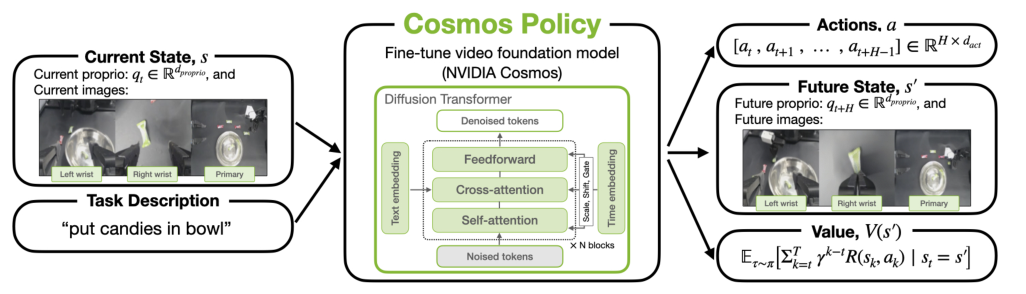

[Cosmos Policy, original Fig. 1](https://proceedings.iclr.cc/paper_files/paper/2026/hash/748becc400a57c0e31cfe6a2e7951467-Abstract-Conference.html). Video pretraining followed by robot post-training; actions, future observations, and values share the latent sequence.

Checkpoint top-level: ['net.accum_video_sample_counter', 'net.accum_image_sample_counter', 'net.accum_iteration', 'net.accum_train_in_hours', 'net.x_embedder.proj.1.weight']


,operation,seconds,allocated_GiB,reserved_GiB,repeats
0,Cosmos: full model load + observation encode,7.66,8.617,8.713,1


,operation,seconds,allocated_GiB,reserved_GiB,repeats
0,"Cosmos: joint sampling, 5 steps (warm)",9.254,8.07,8.719,3


,operation,seconds,allocated_GiB,reserved_GiB,repeats
0,Cosmos: decode causal prefix,3.862,8.729,8.863,1


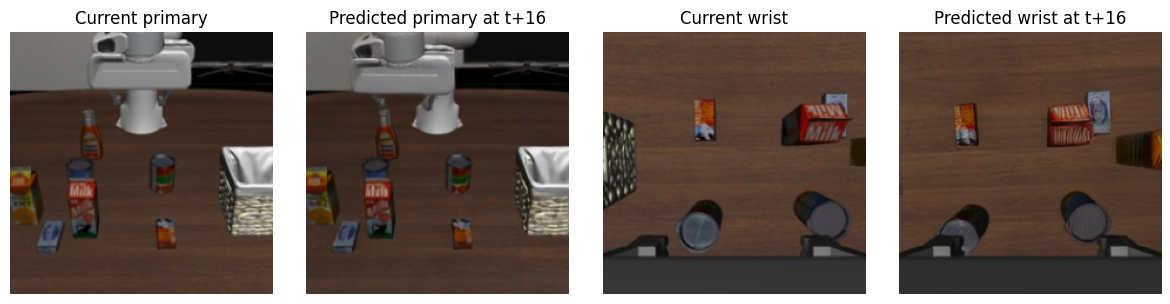

Instruction: put both the alphabet soup and the tomato sauce in the basket


In [5]:
#@title Load the full Cosmos Policy 2B and generate a baseline
cosmos=measure('Cosmos: full model load + observation encode',lambda:CosmosPolicyTuring(WEIGHTS,ROOT/'data'))
METRICS['cosmos_parameters']=cosmos.params
METRICS['cosmos_runtime_keys_excluded']=cosmos.excluded_runtime_keys
cosmos.sample(steps=1)  # Warm the network, with a separate sampler call.
base=measure('Cosmos: joint sampling, 5 steps (warm)',lambda:cosmos.sample(seed=7,steps=5),repeats=3)
cosmos_future=cosmos_gallery(cosmos,base)
print('Instruction:',cosmos.texts[0])

## 1. Read robot commands from a latent slot

**Goal:** turn slot 4, `frame: [B,16,28,28]`, into an action chunk.

- `horizon = 16`: consecutive robot commands.
- `action_dim = 7`: numbers per command. The 16 latent channels are a separate dimension.
- One slot holds **12,544** numbers; one chunk needs **112**.
- Training fills the slot with repeated copies of that chunk. Copies add no commands; predicted copies may differ.

**TODO — `action_readout`:**

1. Flatten each batch item; compute `repeats = slot_length // (horizon * action_dim)`.
2. Discard any incomplete tail; reshape to `[B,repeats,horizon,action_dim]`.
3. Average over copies → `[B,horizon,action_dim]`. Use the arguments, not hard-coded sizes.

**Tokens:** 2 × 2 spatial patches across 16 channels → 196 patches of 64 values.
`196 × 64 = 12,544`; each patch becomes a DiT token. This grouping differs from grouping action copies.

Predict below, complete the function, then run the three checks: original readout, incomplete tail, pack/readout round trip.

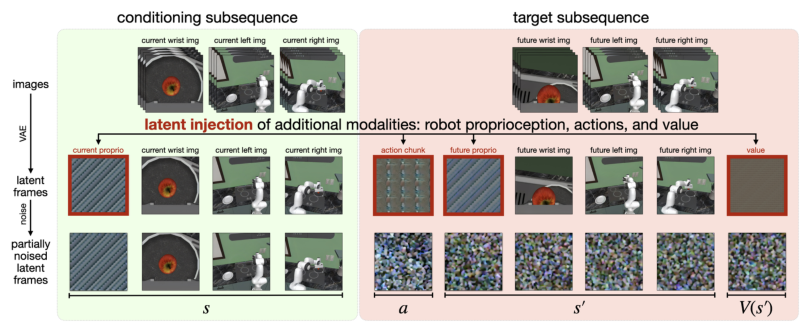

[Cosmos Policy, Fig. 2](https://proceedings.iclr.cc/paper_files/paper/2026/hash/748becc400a57c0e31cfe6a2e7951467-Abstract-Conference.html). Paper: three cameras, blank slot omitted. **Our checkpoint: two cameras, nine slots**, as listed above.

In [6]:
def action_readout(frame, horizon, action_dim):
    # frame: [B, C, H, W] for one latent slot; flatten every non-batch dimension.
    flat = frame.flatten(1)                                    # [B, slot_length]
    chunk_elements = horizon * action_dim                      # one command chunk
    repeats = flat.shape[1] // chunk_elements                  # complete copies only
    kept = flat[:, :repeats * chunk_elements]                  # discard any incomplete tail
    kept = kept.reshape(flat.shape[0], repeats, horizon, action_dim)
    return kept.mean(dim=1)                                    # [B, horizon, action_dim]


PASS: Action readout matches upstream
PASS: Partial repeat is excluded
PASS: Encode/readout round trip


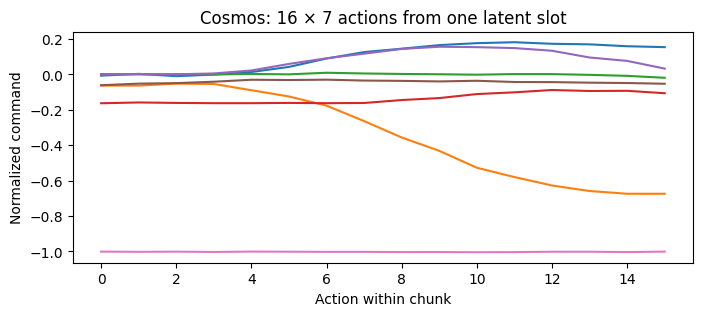

,slot,meaning,DiT tokens
0,0,blank,196
1,1,current proprio,196
2,2,current wrist,196
3,3,current primary,196
4,4,actions,196
5,5,future proprio,196
6,6,future wrist,196
7,7,future primary,196
8,8,value,196


Latent: (1, 16, 9, 28, 28) DiT tokens: 1764 network parameters: 1956413440
def extract_action_chunk_from_latent_sequence(
    output_latent: torch.Tensor, action_shape: tuple, action_indices: torch.Tensor
) -> torch.Tensor:
    """
    Extract the predicted action chunk from the generated latent sequence.

    Args:
        output_latent (torch.Tensor): The full latent sequence generated by the model, with shape (B, C', T', H', W')
        action_shape (tuple): Target shape of the action chunk: (chunk_size, action_dim)
        action_indices (torch.Tensor): Batch indices specifying which index of the latent sequence contains the action

    Returns:
        torch.Tensor: Batch of extracted action chunks, with shape (B, chunk_size, action_dim)
    """
    # Get the action latent frame
    batch_indices = torch.arange(output_latent.shape[0], device=output_latent.device)
    action_latent_frame = output_latent[batch_indices, :, action_indices, :, :]  # (B, C', H', W')
    # Get shape of l

In [7]:
readout_experiment(cosmos,base,action_readout)
source_excerpt(cosmos_ref.extract_action_chunk_from_latent_sequence,lines=38)

**TODO — answer here.** Predict before running; complete the rest afterwards.

1. Is the VAE decoder needed to read actions? Why? **Prediction:** No. Actions are plain numbers stored in slot 4 of the latent sequence, so the readout is arithmetic — flatten the slot, split it into complete copies of the 112-value chunk, average the copies — and never touches an image latent. The VAE decoder is only needed for the camera slots (6 and 7) to turn features back into pixels. I expect all three checks to pass, including the pack/readout round trip, because packing and readout invert the same flattening. *(measured: all three checks printed PASS, and slot 4 needs no VAE decoding)*
2. Calculate `repeats`. Why are 196 DiT tokens different from 16 robot commands? **Explanation:** Slot 4 holds `16 × 28 × 28 = 12,544` numbers and one command chunk is `16 × 7 = 112`, so `repeats = 12544 // 112 = 112` complete copies. The 196 DiT tokens are a different grouping of the same numbers: 2 × 2 spatial patches over the 16 latent channels give `196 × 64 = 12,544`, and each patch becomes one token for the network — the run prints `DiT tokens: 1764` for the nine slots (`9 × 196`) and `network parameters: 1956413440`. So 196 tokens are not 16 commands: tokens are how the network reads the slot, the 112 copies are redundant storage of one 16 × 7 chunk, and averaging the copies is what turns that storage back into commands.
3. Did all three checks pass? What do they establish, and what remains untested? **Evidence:** All three printed `PASS:` — `Action readout matches upstream` (agrees with the pinned `extract_action_chunk_from_latent_sequence`), `Partial repeat is excluded` (a 75-value tensor with a non-divisible tail returns only the mean of the 12 complete copies), and `Encode/readout round trip` (packing a chunk into slot 4 and reading it back returns the same values). That establishes readout and packing as inverse arithmetic on the same flattening, driven by the passed `horizon` and `action_dim` rather than hard-coded sizes. What stays untested: whether the predicted commands are physically correct — nothing was executed — and whether this pure-PyTorch adapter matches NVIDIA's native runtime numerically, which the notebook states has not been measured.

## 2. Keep the known slots fixed

**Goal:** predict the future without changing the supplied present.

- `x`: noisy tensor; `velocity`: model output; `t = sigma / (1 + sigma)`: noise level.
- **`clean`: known slot values**, in the same shape as `x`. Example: `clean[:,:,3]` is the observed primary-camera latent.
- **`mask = 1`: known** → preserve `clean`. **`mask = 0`: unknown** → use the prediction.

**TODO — `conditioned_readout`:** compute the estimate below, then select `clean` or the estimate using the mask.
No derivation is required; `clean` does not supply the unknown future.

$$\hat{x}=(1-t)x-t\,\mathrm{velocity}.$$

| Ask the model for… | Fix slots | Generate slots |
|---|---|---|
| Actions + consequences | 0–3: present | 4–8 |
| Consequences of given actions | 0–4: present + actions | 5–8 |
| Value of a given future | 0–7: also fix future | 8 |

Run the checks: your formula on test tensors; separately, fixed observations in the actual sampler.
**Five denoising steps refine all 16 commands; they do not execute them.**

In [8]:
def conditioned_readout(x, velocity, t, clean, mask):
    # Denoising estimate: x_hat = (1 - t) * x - t * velocity.
    estimate = (1.0 - t) * x - t * velocity
    # mask == 1 marks a known slot, so keep `clean` there and use the estimate elsewhere.
    return estimate * (1.0 - mask) + clean * mask


In [9]:
clamp_experiment(cosmos,base,conditioned_readout)

PASS: Denoising with fixed observations
PASS: Known slots remain exact
Unclamped known-slot MAE: 0.8483812212944031
def replace_latent_with_proprio(x0: torch.Tensor, proprio: torch.Tensor, proprio_indices: torch.Tensor) -> torch.Tensor:
    """
    Replaces the image latent (at the specified proprio index) in clean input image latents x0 with the proprio.

    Example:
    Let's say x0 has shape (B=32, C'=16, T', H'=28, W'=28) and proprio has shape (B=32, proprio_dim=9).
    Then, this function will overwrite the (C'=16, H'=28, W'=28) volume at x0[:,:,proprio_indices,:,:] with the proprio,
    repeating it as many times as needed to fill the entire volume.

    Args:
        x0 (torch.Tensor): Clean image latents.
        proprio (torch.Tensor): Ground-truth proprio.


## 3. Change the actions; compare the predicted futures

**Goal:** check whether the forecast responds to the supplied commands.

Run the ready-made experiment with **sampled**, **normalized-zero**, and **time-reversed** commands.
Fix slots 0–4; regenerate 5–8. Keep observation, instruction, noise seed, and budget identical.
Each run uses one denoising step to predict the endpoint after all 16 commands.

**Read the output:**

| Output | What is compared with the sampled-action prediction? |
|---|---|
| Future latent MAE | Mean absolute difference of all numbers in slots 5–7, before decoding |
| Per-slot MAE | 5: robot state; 6: wrist camera; 7: displayed primary camera |
| RGB difference maps | Absolute pixel differences, averaged over RGB channels, after decoding |

$$\mathrm{MAE}_{\mathrm{latent}}=\mathrm{mean}\left(|z_{5:8}-z^{\mathrm{reference}}_{5:8}|\right).$$

MAE = 0.1 means an average latent change of 0.1, **not 10% image error**.
The reference is regenerated with matching noise and budget; its difference from itself is zero.

Maps share one colour scale in 0–255 intensity units, stretched to the observed differences.
Their titles show whole-image means. **Similar-looking forecasts are a valid result.**
We compare predictions with predictions, not with a real future: sensitivity does not prove accuracy.

,operation,seconds,allocated_GiB,reserved_GiB,repeats
0,Cosmos conditional: sampled action,1.919,8.068,8.863,1


PASS: Fixed action: sampled action


,operation,seconds,allocated_GiB,reserved_GiB,repeats
0,Cosmos conditional: zero normalized action,1.931,8.068,8.863,1


PASS: Fixed action: zero normalized action


,operation,seconds,allocated_GiB,reserved_GiB,repeats
0,Cosmos conditional: reverse temporal order,1.936,8.068,8.863,1


PASS: Fixed action: reverse temporal order
Mean absolute difference from the sampled-action prediction (latent values, before VAE decoding):


,action intervention,all future slots (5–7),robot state (5),wrist image (6),primary image (7)
0,sampled action,0.000000,0.000000,0.000000,0.00000
1,zero normalized action,0.100194,0.019621,0.194531,0.08643
2,reverse temporal order,0.063659,0.008096,0.128181,0.05470


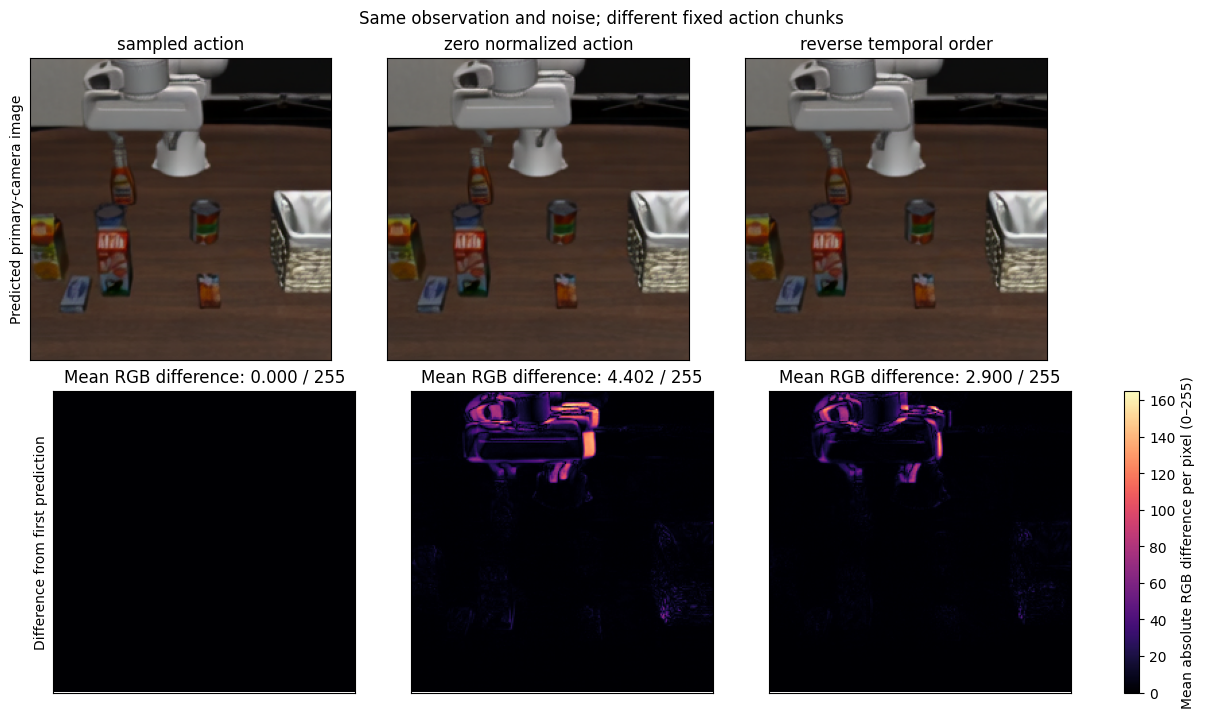

In [10]:
cosmos_intervention_outputs=cosmos_interventions(cosmos,base)

**TODO — answer here.** Predict before running; complete the rest afterwards.

1. Will reversing commands change the forecast? Why? **Prediction:** Yes. Commands are injected into slot 4 and every DiT token attends across slots, so a time-reversed command sequence is a different conditioning and the endpoint forecast in slots 5–7 must move away from the sampled baseline. I expect the largest change in slot 5 (future robot state, the slot most directly derived from the commands) and smaller changes in the wrist/primary camera slots, with a real but modest latent MAE — the model is action-sensitive, not deterministic about the future. *(measured: it did change — 0.063659 latent MAE over slots 5–7, 2.900/255 RGB — but the wrist latent moved most, not the robot-state slot)*
2. Report latent and RGB differences for both variants. Which slot changes most, and where do the maps show changes? **Evidence:** Latent MAE against the sampled-action forecast: `zero normalized action` gives **0.100194** over slots 5–7, **0.019621** in robot state (5), **0.194531** in wrist (6) and **0.08643** in primary (7); `reverse temporal order` gives **0.063659 / 0.008096 / 0.128181 / 0.05470**; the sampled reference is **0.000000** everywhere because it is compared with itself. After decoding, whole-image mean RGB differences are **0.000 / 4.402 / 2.900** out of 255, and the maps place the bright pixels (120–160 intensity) on the arms and grippers while the objects, basket and table stay near black. So reversal does move the forecast, but less than the zero command, and the largest latent shift is in the **wrist** slot rather than proprio — my prediction on that detail was wrong. Latent MAE is not directly comparable across slots because their numbers live on different scales; the RGB maps are the shared one.
3. Why fix the noise? Does setting every normalized action component to zero keep the robot still? Explain using the action normalization and control convention. What would test physical accuracy? **Explanation:** The noise and seed are fixed because the sampler is a stochastic rectified-flow step: if noise, seed and step budget all changed together with the commands, a changed forecast could not be attributed to the commands. Keeping them identical leaves the action chunk as the only variable. Normalized zero is not "hold": the checkpoint's min/max normalization maps the physical range into `[-1, 1]`, so 0 is the **mid-point** of that range — an absolute joint target at the centre of the trained range, not "stay where you are"; only a delta-encoded channel would read 0 as no motion. Physical accuracy would need execution: run each command chunk in the LIBERO simulator from the same observation and score the outcome against a recorded future — and this data has none (`observed_future: false` in the manifest), so the current comparison is prediction against prediction.

## 4. Choose commands using imagined futures

**Why:** model-based planning compares consequences before acting.
Cosmos Policy uses this approach on real ALOHA robots. [Paper, §4.3](https://arxiv.org/html/2601.16163v1#S4.SS3).

**The supplied search:**

1. Fix slots 0–3 → generate **3 action candidates** (5 denoising steps each).
2. Fix slots 0–4 → generate **3 futures per candidate** (1 step each).
3. Fix slots 0–7 → predict **value in slot 8** for each future (1 step).

Different noise seeds produce alternatives. Future seeds are paired across candidates; the value seed stays fixed.
`scores[i,j]` is the value of candidate `i` under future sample `j`: **rows = candidates, columns = futures**.

**TODO — `select_candidate`:** average each row, then return the index of the largest mean.
Run the checks and search; compare row means and winners in each column. Higher value means higher predicted future reward.

**How this teaching search differs from the published ALOHA planner**

Both searches propose action chunks, predict their consequences, score them, and select a candidate.
They differ in the models used and in how the scores are collected and combined.

| For each action candidate | This notebook | Published ALOHA planner |
|---|---|---|
| Model checkpoints | One checkpoint for actions, futures, and value | Original policy checkpoint for actions; a separately refined planning checkpoint for futures and value |
| Alternative futures | 3 | 3 |
| Value samples per future | 1 | 5 |
| Total value estimates | 3 | 15 |
| Candidate score | Mean of all 3 values | Majority mean over the 15 values |

**Why a separate planning checkpoint?** A rollout is an episode obtained by executing a policy in an environment.
The authors collect the policy's actual transitions and task outcomes, including failures, and further train the
planning model on these data. This helps it learn the consequences of the proposing policy's own actions and errors.
Demonstrations alone may provide too little coverage of unsuccessful outcomes for reliable planning.
Our notebook uses one unchanged checkpoint for all three roles; conditioning masks determine the requested output.

**Why five values for the same future?** Value is generated stochastically, so repeated sampling can give different
estimates even when the action and predicted future are fixed. The published planner samples three alternative
futures and then five values for each: 3 × 5 = 15 estimates per candidate. These are model predictions, not fifteen
executions in the environment. Our code obtains one value per future, using a fixed value seed.

**How does majority mean work?** A fixed threshold separates the fifteen estimates into predicted-success and
predicted-failure groups. The planner keeps the group containing the majority of estimates and averages only that
group's values. For example, if nine estimates predict failure and six predict success, it averages the nine
failure-group values. This limits the influence of the minority group when predictions split into two clusters.
The threshold-based grouping does not make raw value scores calibrated success probabilities.
For this exercise, implement the simpler rule: average all three values in each row, then select the largest mean.

**What we can conclude:** this single-observation LIBERO experiment demonstrates the selection mechanism.
It does not reproduce the paper's measured improvement on ALOHA: the checkpoint setup and aggregation differ,
and we do not execute commands or measure task success. Small score gaps establish a model ranking, not better
real control. To test a planning benefit, compare the direct policy and the planner by execution over multiple
matched initial conditions and repeated trials. See [Paper, §4.3](https://arxiv.org/html/2601.16163v1#S4.SS3).

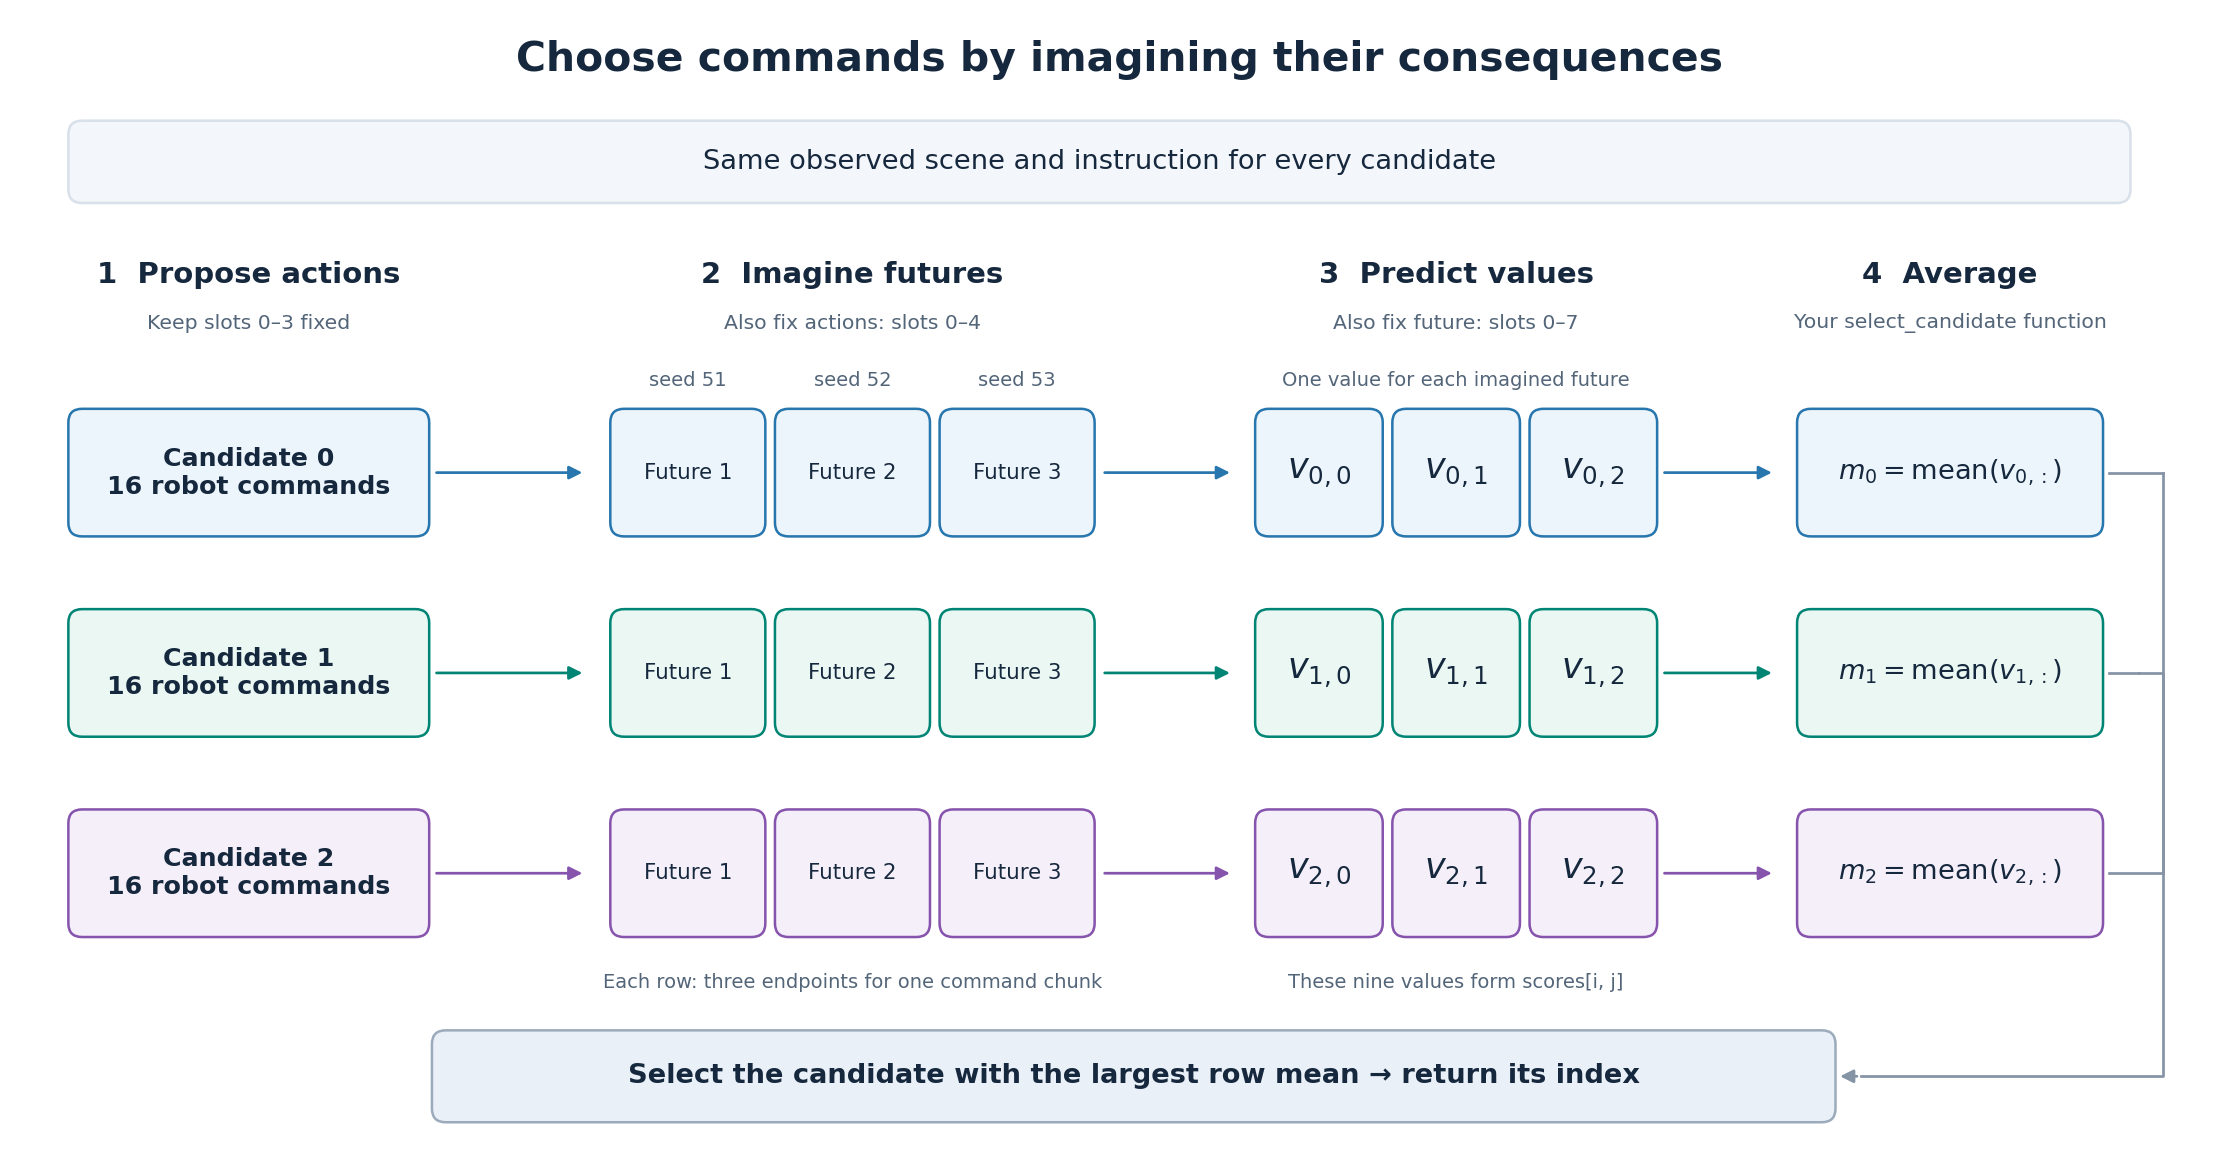

**Read each row:** commands → three alternative endpoints → values → mean. The nine values form `scores[i,j]`. Futures are alternatives, not consecutive frames. Teaching schematic of our simplified search.

In [11]:
def select_candidate(scores):
    # scores[i, j] = value of candidate i under imagined future j (rows = candidates).
    scores = np.asarray(scores)
    row_means = scores.mean(axis=1)          # average the future replicas of each candidate first
    return int(np.argmax(row_means))         # index of the candidate with the largest mean value


PASS: Candidate selection
PASS: Average replicas before selecting


,future seed 51,future seed 52,future seed 53,mean,selected
0,-0.868334,-0.868192,-0.868224,-0.868250,False
1,-0.868446,-0.868330,-0.868331,-0.868369,False
2,-0.867790,-0.867669,-0.867687,-0.867715,True


Selected candidate: 2 First physical command: [ 7.54706562e-04 -4.92649712e-02  1.75897032e-03 -1.24701127e-03
  4.11361456e-04 -1.37809944e-02 -9.99109924e-01]


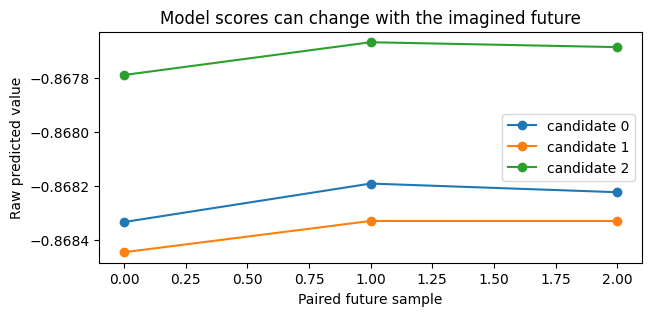

,operation,seconds,allocated_GiB,reserved_GiB,repeats
0,Cosmos: candidate → future → value search,60.061,8.072,8.865,1


In [12]:
cosmos_scores=measure("Cosmos: candidate → future → value search",lambda:cosmos_candidates(cosmos,base,select_candidate))

**Source:** [sampling](https://github.com/NVlabs/cosmos-policy/blob/18a2accadf4e7a3531e56754102af5a24d2316da/cosmos_policy/experiments/robot/cosmos_utils.py) · [training](https://github.com/NVlabs/cosmos-policy/blob/18a2accadf4e7a3531e56754102af5a24d2316da/cosmos_policy/config/experiment/cosmos_policy_experiment_configs.py).
Value uses discounted-return targets from successes and failures; raw scores are not calibrated success probabilities.

**TODO — answer here.** Predict before running; complete the rest afterwards.

1. Will one candidate win for every future seed? **Prediction:** No, not necessarily. Each column is a different imagined endpoint drawn with its own noise seed, so per-column winners can differ from the row-mean winner. I expect the best candidate to win most but not all three futures, and the gaps between row means to be small enough that one unlucky future could flip the selection. *(measured: candidate 2 won every column, so the prediction was half right — rankings were stable, but scores did move with the imagined future)*
2. Report the row means and winner. Does it win every column? Why average before selecting? **Evidence:** Row means: candidate 0 **-0.868250**, candidate 1 **-0.868369**, candidate 2 **-0.867715**, and the run prints `Selected candidate: 2`. Candidate 2 also wins all three columns individually (-0.867790, -0.867669, -0.867687), so the risk I predicted — a winner losing one column — did not materialize here; still, within a single candidate the score moves with the imagined future (candidate 0 ranges from -0.868334 to -0.868192 across the three seeds), which is what the plotted lines show. Averaging before selecting is necessary because the three futures are alternative endpoints from different noise seeds, not consecutive frames: choosing on one column would let a single lucky or unlucky sample decide the command, while the row mean uses all three.
3. Do small value differences imply better real actions? What execution-based test is needed? **Explanation:** No. The gap between the best and worst row mean is **0.000654** and the within-candidate spread across futures is about **0.00014**, while these raw scores are uncalibrated predicted values from one checkpoint combined by a simple mean — not probabilities of success. The commands were never executed, so nothing here shows better real control. The execution-based test would be closed-loop: run each candidate chunk in the simulator from the same observation over many seeds, measure task success and return, and compare those outcomes with the predicted values — the paper's planner also uses a rollout-refined checkpoint and majority aggregation over 3 futures × 5 values, not this 3 + 1 teaching version.

In [13]:
#@title Release Cosmos before loading UVA
cosmos.close()
del cosmos,base,cosmos_intervention_outputs,cosmos_future
gc.collect();torch.cuda.empty_cache()

## UVA · separate action and video branches

UVA unifies video and actions in a shared latent representation, while separating their generation into two heads.
This allows the jointly trained representation to be used for control without generating video at every inference call.

**After planning with futures, ask: can direct control skip video?**

| Cosmos | UVA (Unified Video Action) |
|---|---|
| Actions and images share one latent diffusion sequence | Shared representation → separate action and video heads |
| Read actions from their slot | Generate commands with the action head |

A **head** is an output branch. UVA's video head generates image latents; the VAE decoder turns them into pixels.

**Example:** full PushT checkpoint. A pusher moves a T-shaped block towards a target.
The initial observation is repeated into a 16-step history; four selected frames are encoded once for both paths.
Outputs: **16 commands** (2D target positions), optionally **4 predicted images** at +4/+8/+12/+16 commands.
We compare inference paths without executing commands.

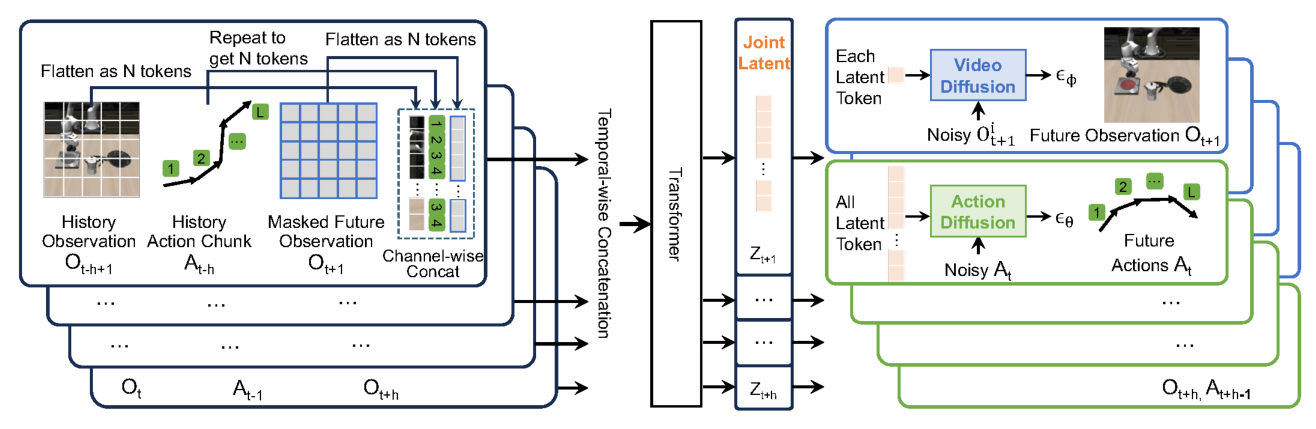

[UVA, original Fig. 2](https://www.roboticsproceedings.org/rss21/p074.html). Shared video–action representation and decoupled diffusion heads. Follow the two output branches: action inference can skip the video branch.

UVA: full EMA state, 1 refinement iteration, 100 diffusion steps per head
Working with z of shape (1, 16, 16, 16) = 4096 dimensions.
----------------------------------------------------------------------
task_modes ['video_model', 'dynamic_model', 'policy_model', 'inverse_model', 'full_dynamic_model']
----------------------------------------------------------------------


,operation,seconds,allocated_GiB,reserved_GiB,repeats
0,UVA: full EMA load + history encode,24.449,1.872,2.123,1


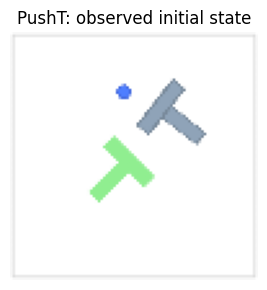

Initial state seed: 100000 Parameters: 327535205


In [14]:
#@title Load full UVA weights and obtain the initial PushT observation
uva=measure('UVA: full EMA load + history encode',lambda:UVALab(WEIGHTS))
METRICS['uva_parameters']=uva.params
gallery([uva.initial_rgb],['PushT: observed initial state'])
print('Initial state seed:',uva.seed,'Parameters:',uva.params)

## 5. Can UVA act without generating video?

**Goal:** check whether skipping the video branch changes the commands.

| Path | Requested output |
|---|---|
| `policy_model` | Actions only |
| `full_dynamic_model` | Actions + future latents; then decode images |

Predict below, then **run the supplied cell**. No coding TODO.
Both paths use the same weights, encoded history, seed, temperature, and **one refinement iteration**.
That is one outer pass, distinct from 100 denoising steps per head and 16 output commands.

**Compare:**

1. **Command difference between modes:** compare the normalized x/y targets at each of the 16 steps,
   then report the largest absolute difference: `max(abs(actions_policy - actions_full))`.
   Zero means every command coordinate matches; this is not movement between consecutive steps.
2. Calls to `action_head`, `video_head`, and `vae_decode` (latents → pixels).
3. The early `return` in the printed source: which work is skipped?

Each head call includes its denoising steps; VAE decoding runs once per displayed frame.
Observation encoding is outside the timings. Policy is warmed up; the video head is not, so timings do not establish a precise speedup.
**Equality is tested for one refinement with matched randomness, not every inference setting.**

,operation,seconds,allocated_GiB,reserved_GiB,repeats
0,UVA: policy only (warm),0.523,1.342,2.123,1


,operation,seconds,allocated_GiB,reserved_GiB,repeats
0,UVA: joint actions + latent video,3.113,1.342,2.123,1


,operation,seconds,allocated_GiB,reserved_GiB,repeats
0,UVA: decode four future frames,0.249,1.36,2.127,1


PASS: One-iteration UVA action equality
Maximum absolute action difference (normalized coordinates): 0.0
PASS: UVA policy skips video sampling and decoding
PASS: UVA joint samples both heads and decodes four frames


,video_head,action_head,vae_decode
policy,0,1,0
joint + decode,1,1,4


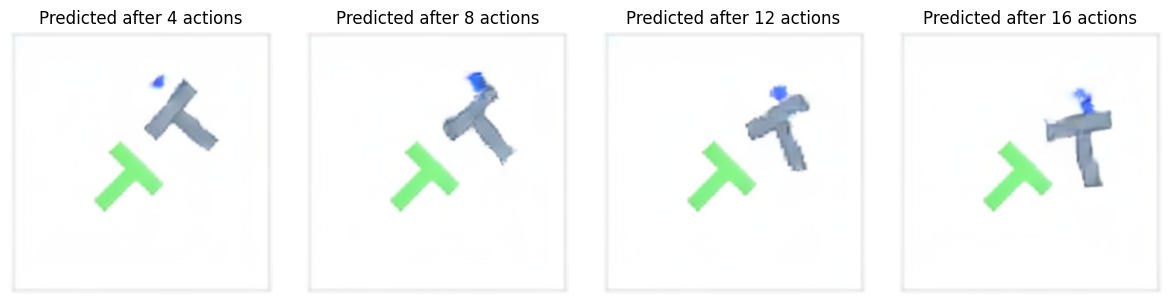

                if self.predict_action:
                    act_cfg = 1.0
                    sampled_token_latent_act = self.diffactloss.sample(
                        z, temperature, cfg=act_cfg, text_latents=text_latents
                    )
                else:
                    sampled_token_latent_act = None

                # ========= Predict action and return if task_mode is inverse_model or policy_model=========
                if task_mode == "inverse_model" or task_mode == "policy_model":
                    return None, sampled_token_latent_act

                # ========= Mask Ratio =========


In [15]:
uva_actions,uva_latents,uva_predicted=uva_decode_ablation(uva)
source_excerpt(type(uva.model).sample_tokens,'if self.predict_action:',lines=13)

**TODO — answer here.** Predict before running; complete the rest afterwards.

1. Predict: will the 16 robot commands from `policy_model` (actions only) match those from
   `full_dynamic_model` (actions + predicted video), given the same observation and random seed?
   **Prediction and reason:** They should match exactly — `max(abs(actions_policy - actions_full)) == 0` over all 16 x/y targets. With one refinement iteration the loop body runs once: `z` comes out of the shared representation before any video-branch work, and the action head is sampled from that `z` with `cfg=1.0` before the early `return None, sampled_token_latent_act` that `task_mode == "policy_model"` takes. Everything the early return skips — the later MaskGIT iterations, `diffloss.sample` for the video and wrist heads, unpatchify and the VAE decode — runs *after* the action sample in the full path, so it cannot feed back into it within a single iteration. Both paths share the encoded history and are seeded identically, so the action head's noise draws start from the same RNG state. Timings will still differ: the policy is warmed up while the video head is not. *(measured: exactly 0.0 difference — the prediction held)*
2. Report the largest command-coordinate difference between the two modes and their call counts.
   What is skipped, and what still runs? **Evidence:** The commands were identical: `Maximum absolute action difference (normalized coordinates): 0.0`, with `PASS: One-iteration UVA action equality`. Call counts: `policy → video_head 0, action_head 1, vae_decode 0` versus `joint + decode → video_head 1, action_head 1, vae_decode 4`. Timings: policy-only warmed **0.523 s**, joint actions + latent video **3.113 s**, decoding the four future frames **0.249 s**, with **1.342 GiB** allocated / **2.123 GiB** reserved. Skipped by the early return: the later MaskGIT iterations, the video head's `diffloss.sample`, the wrist head, unpatchify and every VAE decode. Still executed in the policy path: the history encode, one `forward_mae_encoder`/`forward_mae_decoder` pair that produces `z`, and the action head's denoising steps.
3. Explain the early return and contrast with Cosmos. Why are the timing and equality conclusions limited? **Explanation:** The early `return None, sampled_token_latent_act` taken when `task_mode` is `policy_model` (or `inverse_model`) leaves the video branch entirely unexecuted — the returned `None` is the unpatchified video tensor — which is exactly what the zero `video_head` and `vae_decode` counts show. Cosmos is organized differently: actions, future observations and value are slots of one latent sequence generated jointly, so there is no "actions only" path; skipping video there means skipping slots 6 and 7 inside the same denoising, not bypassing a separate head. Both conclusions are bounded: the timing comparison is not a speedup measurement because the policy was warmed up and the video head was not, so the joint call pays first-run costs; and equality was tested only for one refinement iteration with matched history, seed and temperature — with a second iteration the generated video latents would feed back into `z`, and the two paths could then diverge.

In [16]:
#@title Save local measurements and release GPU memory
save_report(ROOT)
uva.close()
del uva,uva_actions,uva_latents,uva_predicted
gc.collect();torch.cuda.empty_cache()

,operation,seconds,allocated_GiB,reserved_GiB,repeats
0,Cosmos: full model load + observation encode,7.660,8.617,8.713,1
1,"Cosmos: joint sampling, 5 steps (warm)",9.254,8.070,8.719,3
2,Cosmos: decode causal prefix,3.862,8.729,8.863,1
3,Cosmos conditional: sampled action,1.919,8.068,8.863,1
4,Cosmos conditional: zero normalized action,1.931,8.068,8.863,1
5,Cosmos conditional: reverse temporal order,1.936,8.068,8.863,1
6,Cosmos: candidate → future → value search,60.061,8.072,8.865,1
7,UVA: full EMA load + history encode,24.449,1.872,2.123,1
8,UVA: policy only (warm),0.523,1.342,2.123,1
9,UVA: joint actions + latent video,3.113,1.342,2.123,1


**Sources and reproducibility.** [Cosmos Policy paper](https://proceedings.iclr.cc/paper_files/paper/2026/hash/748becc400a57c0e31cfe6a2e7951467-Abstract-Conference.html) · [UVA paper](https://www.roboticsproceedings.org/rss21/p074.html).
Cosmos source `18a2accadf4e7a3531e56754102af5a24d2316da`; UVA source `fe3dec81af565fbb2d686072722f12340be31293`.
Original Cosmos injection/readout/sampler functions and original UVA inference modules are bundled with licenses.
The pure-PyTorch Cosmos DiT/Wan VAE infrastructure comes from
[this port](https://github.com/iitimii/SmolWAM/tree/dde1e5bfe35c439499343c6d70e9cd32c96d0b36/smolwam/nn), retaining full Cosmos depth and weights;
no SmolWAM checkpoint is used. Changing kernels/dtype has not been compared numerically with NVIDIA's native runtime.
Large weight files are checked by SHA-256 before loading. UVA's release contains `ema_model` only; its complete state is loaded strictly.

These are mechanism probes: one recorded LIBERO observation and two UVA inference paths from one initial PushT state.
Commands are not executed in this shortened seminar; no task-success or physical prediction-accuracy claim is tested.
Rerun the weight-download cell to resume an interrupted download.